# Sensor Fault Detection with Deutsch’s Algorithm
### Quantum Computing — Third Internal Project
**Repository:** Jeshurun_QC • **Platform:** Google Colab + Qiskit • **Scope:** individual learning project

> A one-bit sensor implements a hidden Boolean rule $f:\{0,1\}\to\{0,1\}$. A constant rule is **faulty**; a balanced rule is **working**. Can we classify it with one oracle query?

This notebook contains the complete implementation, circuits, mathematical derivation, reproducible simulation results, figures, validation, and analysis. Run the cells from top to bottom. Saved outputs allow offline inspection; rerunning regenerates the figures. No external dataset, API key, or quantum hardware is required.

**Learning ownership:** Read the derivation, change the experimental settings, and answer the viva prompts at the end before presenting. Add your own name, register number, and observations. This implementation is a learning aid; it does not certify independent authorship or replace your institution’s disclosure rules.

## 1. Aim, syllabus alignment, and scope
**Aim:** construct every possible reversible sensor oracle, classify each using Deutsch’s algorithm, and compare exact theory with measured simulation.

| Syllabus module | Concepts used here | Evidence in this notebook |
|---|---|---|
| 1 — Introduction to Quantum Mechanics | State vectors, superposition, postulates, Bloch representation | Derivation and Bloch-vector trace |
| 2 — Quantum Gates and Circuits | Qubits, X/H, controlled gates, multiple-qubit circuits | Four oracles and circuit diagrams |
| 3 — Entanglement and Quantum Protocols | Measurement; distinguishing entanglement from superposition | Measurement rule and separability discussion |
| 4 — Quantum Algorithms I | Circuit versus query complexity; Deutsch’s algorithm | One-query classification and classical comparison |
| 6 — Quantum Applications (extension) | Effect of errors | Optional synthetic readout-noise experiment |

Module 5’s QFT and phase-estimation algorithms are outside this problem’s scope. The noise extension does not implement quantum error correction.

**Deliverables:** four oracle circuits; four full Deutsch circuits; exact and sampled outcome tables; probability, state-evolution, query-count, and noise plots; executable correctness checks; limitations and viva questions.

## 2. Runtime setup — Google Colab
Use a **Python 3 CPU** runtime (GPU is unnecessary). Run this installation cell first. These package versions are pinned to the environment used to validate this notebook. If packages were already imported before installation, restart the runtime once, then run all cells again. Installation requires internet; the experiment itself runs locally.

In [1]:
%pip -q install qiskit==2.6.1 qiskit-aer==0.18.2 matplotlib==3.11.2 pandas==3.1.0 pylatexenc==2.11 ipywidgets==8.1.9


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import sys, platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator, partial_trace, Pauli
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError

plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
SEED = 42
SHOTS = 1024  # repeated independent one-query executions for statistics
assert isinstance(SHOTS, int) and SHOTS > 0
print('Python:', platform.python_version())
display(pd.DataFrame({'Package': ['qiskit', 'qiskit-aer', 'numpy', 'pandas', 'matplotlib'],
                      'Version': [metadata.version(p) for p in
                                  ['qiskit', 'qiskit-aer', 'numpy', 'pandas', 'matplotlib']]}))

Python: 3.12.14


,Package,Version
0,qiskit,2.6.1
1,qiskit-aer,0.18.2
2,numpy,2.5.4
3,pandas,3.1.0
4,matplotlib,3.11.2


## 3. Problem model and all four functions
There are $2^{2^1}=4$ Boolean rules. **Constant** means $f(0)=f(1)$; **balanced** means the two outputs differ. The diagnostic bit is $d=f(0)\oplus f(1)$.

| Function | $f(0)$ | $f(1)$ | Class | Sensor status | Expected $d$ | Oracle decomposition |
|---|---:|---:|---|---|---:|---|
| $f(x)=0$ | 0 | 0 | Constant | Faulty | 0 | Identity |
| $f(x)=1$ | 1 | 1 | Constant | Faulty | 0 | X on target |
| $f(x)=x$ | 0 | 1 | Balanced | Working | 1 | CX, input controls target |
| $f(x)=1\oplus x$ | 1 | 0 | Balanced | Working | 1 | CX then X on target |

**Assumption:** we are given coherent access to the reversible quantum oracle
$$U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle.$$
A physical sensor returning classical bits does not automatically provide this oracle. This is a simulated diagnostic under the stated model. We build known examples to test the algorithm; the classifier itself does not consult the truth table.

**f(x) = 0**

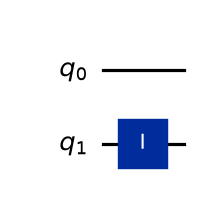

**f(x) = 1**

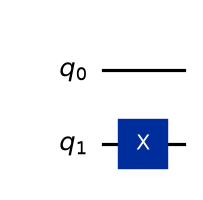

**f(x) = x**

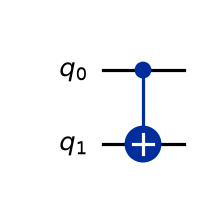

**f(x) = 1 XOR x**

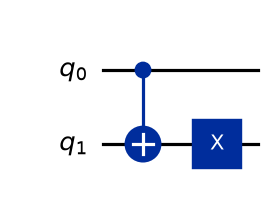

In [3]:
SENSORS = {
    'constant_0': {'label': 'f(x) = 0', 'truth': (0, 0)},
    'constant_1': {'label': 'f(x) = 1', 'truth': (1, 1)},
    'balanced_x': {'label': 'f(x) = x', 'truth': (0, 1)},
    'balanced_not_x': {'label': 'f(x) = 1 XOR x', 'truth': (1, 0)},
}

def build_oracle(key):
    """Return U_f on q0=input and q1=target; no measurement inside."""
    if key not in SENSORS:
        raise ValueError(f'Unknown sensor: {key}')
    oracle = QuantumCircuit(2, name='U_' + key)
    if key == 'constant_0':
        oracle.id(1)
    elif key == 'constant_1':
        oracle.x(1)
    elif key == 'balanced_x':
        oracle.cx(0, 1)
    else:
        oracle.cx(0, 1)
        oracle.x(1)
    return oracle

for key, info in SENSORS.items():
    display(Markdown('**' + info['label'] + '**'))
    display(build_oracle(key).draw('mpl'))
    plt.close('all')

## 4. Verify the reversible oracles independently
For each oracle, check **all four** computational-basis inputs $(x,y)$, including $y=1$. Testing only $y=0$ would miss incorrect XOR behaviour. Also check unitarity.

Qiskit uses little-endian indexing: a two-qubit basis label is $|q_1q_0\rangle=|yx\rangle$, so its array index is $x+2y$. Diagrams still draw $q_0$ on the upper wire. We measure only $q_0$ into one classical bit, so result strings are simply `0` or `1`.

In [4]:
oracle_checks = []
for key, info in SENSORS.items():
    matrix = Operator(build_oracle(key)).data
    assert np.allclose(matrix.conj().T @ matrix, np.eye(4))
    for x in (0, 1):
        for y in (0, 1):
            initial = Statevector.from_int(x + 2*y, dims=(2, 2))
            actual = initial.evolve(build_oracle(key))
            expected_index = x + 2*(y ^ info['truth'][x])
            expected = Statevector.from_int(expected_index, dims=(2, 2))
            assert np.allclose(actual.data, expected.data), (key, x, y)
            oracle_checks.append({'Oracle': key, 'x': x, 'y': y,
                                  'Expected target': y ^ info['truth'][x], 'Pass': True})
display(pd.DataFrame(oracle_checks))
print('PASS: 16 basis-state mappings and 4 unitarity checks.')

,Oracle,x,y,Expected target,Pass
0,constant_0,0,0,0,True
1,constant_0,0,1,1,True
2,constant_0,1,0,0,True
3,constant_0,1,1,1,True
4,constant_1,0,0,1,True
5,constant_1,0,1,0,True
6,constant_1,1,0,1,True
7,constant_1,1,1,0,True
8,balanced_x,0,0,0,True
9,balanced_x,0,1,1,True


PASS: 16 basis-state mappings and 4 unitarity checks.


## 5. Derivation: why one query is sufficient
Use two qubits: input $q_0$ starts in $|0\rangle$ and auxiliary $q_1$ is flipped to $|1\rangle$. In the following equations, tensor factors are written in logical **input, auxiliary** order (unlike Qiskit’s displayed bitstrings).

1. **Prepare:** $|0\rangle|1\rangle$.
2. **Superpose:** $(H\otimes H)|0\rangle|1\rangle=|+\rangle|-\rangle$, where $|\pm\rangle=(|0\rangle\pm|1\rangle)/\sqrt2$.
3. **Query once:** because $X|-\rangle=-|-\rangle$, the target flip becomes a phase on the input:
$$U_f|+\rangle|-\rangle=\frac{(-1)^{f(0)}|0\rangle+(-1)^{f(1)}|1\rangle}{\sqrt2}|-\rangle.$$
4. **Interfere:** apply $H$ to the input:
$$\frac{(-1)^{f(0)}+(-1)^{f(1)}}{2}|0\rangle|-\rangle+
\frac{(-1)^{f(0)}-(-1)^{f(1)}}{2}|1\rangle|-\rangle
= (-1)^{f(0)}|f(0)\oplus f(1)\rangle|-\rangle.$$
5. **Measure:** `0` implies constant/faulty; `1` implies balanced/working, with certainty in the ideal model.

The overall factor $(-1)^{f(0)}$ is a global phase and is unobservable. Thus this experiment distinguishes classes, not the two functions within a class. The auxiliary remains $|-\rangle$ and the state is separable at these stages: entanglement is **not necessary** for this instance, although CX is a two-qubit gate.

**Deutsch circuit — f(x) = 0**

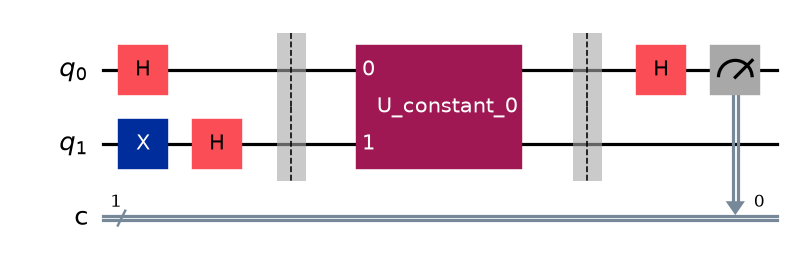

**Deutsch circuit — f(x) = 1**

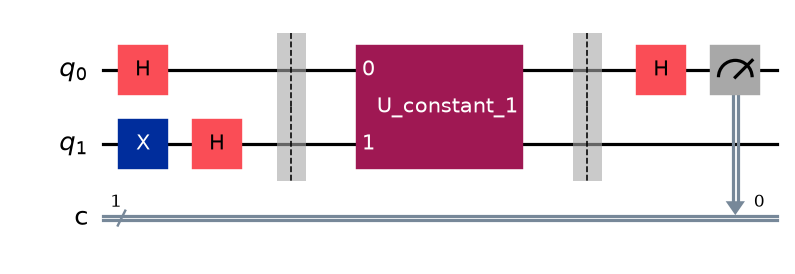

**Deutsch circuit — f(x) = x**

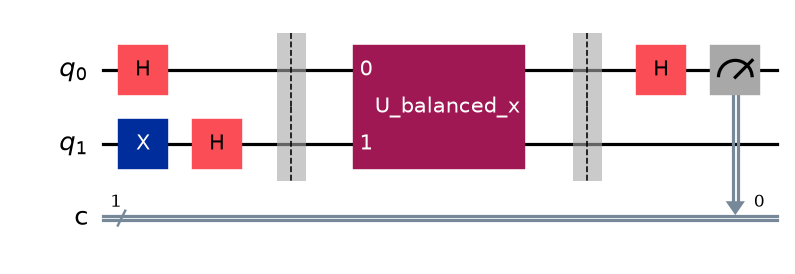

**Deutsch circuit — f(x) = 1 XOR x**

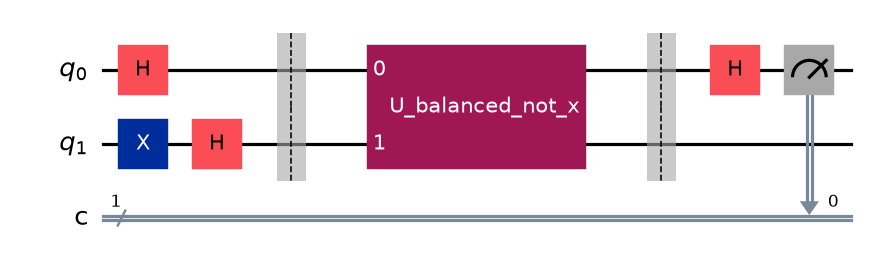

In [5]:
def deutsch_circuit(key, measure=True):
    circuit = QuantumCircuit(2, 1) if measure else QuantumCircuit(2)
    circuit.x(1)
    circuit.h(0)
    circuit.h(1)
    circuit.barrier()
    # Exactly one logical black-box oracle invocation, even for identity U_f.
    circuit.append(build_oracle(key).to_gate(), [0, 1])
    circuit.barrier()
    circuit.h(0)
    if measure:
        circuit.measure(0, 0)
    return circuit

for key, info in SENSORS.items():
    circuit = deutsch_circuit(key)
    assert sum(i.operation.name.startswith('U_') for i in circuit.data) == 1
    display(Markdown('**Deutsch circuit — ' + info['label'] + '**'))
    display(circuit.draw('mpl'))
    plt.close('all')

## 6. Ideal simulation and diagnostic results
Two independent views are used: an exact statevector calculates input-qubit probabilities, while Aer produces repeated measured outcomes. Every shot uses **one** oracle invocation. The four-oracle batch with `SHOTS=1024` uses 4096 oracle invocations in total; it is not a single-query experiment overall.

The simulator necessarily knows the oracle implementation. Query complexity is assessed at the logical black-box boundary before transpilation; compiler simplification may remove identity gates or combine other gates.

In [6]:
ideal_backend = AerSimulator()
keys = list(SENSORS)
compiled = transpile([deutsch_circuit(k) for k in keys], ideal_backend,
                     optimization_level=0, seed_transpiler=SEED)
ideal_result = ideal_backend.run(compiled, shots=SHOTS, seed_simulator=SEED).result()
rows, ideal_counts = [], {}
for i, key in enumerate(keys):
    info = SENSORS[key]
    expected = info['truth'][0] ^ info['truth'][1]
    probabilities = Statevector.from_instruction(deutsch_circuit(key, False)).probabilities([0])
    counts = ideal_result.get_counts(i)
    ideal_counts[key] = counts
    measured_bit = int(max(counts, key=counts.get))
    # The classification depends on measured outcomes, not the reference truth table.
    predicted = 'Faulty' if measured_bit == 0 else 'Working'
    assert np.isclose(probabilities[expected], 1)
    assert counts.get(str(expected), 0) == SHOTS and sum(counts.values()) == SHOTS
    rows.append({'Function': info['label'], 'f(0)': info['truth'][0], 'f(1)': info['truth'][1],
                 'Class': 'Constant' if expected == 0 else 'Balanced',
                 'P(0) exact': round(float(probabilities[0]), 6),
                 'P(1) exact': round(float(probabilities[1]), 6),
                 'Count 0': counts.get('0', 0), 'Count 1': counts.get('1', 0),
                 'Measured bit': measured_bit, 'Sensor diagnosis': predicted,
                 'Queries / execution': 1})
results = pd.DataFrame(rows)
display(results)
print(f'PASS: all four ideal diagnoses match theory ({SHOTS} shots each).')

,Function,f(0),f(1),Class,P(0) exact,P(1) exact,Count 0,Count 1,Measured bit,Sensor diagnosis,Queries / execution
0,f(x) = 0,0,0,Constant,1.0,0.0,1024,0,0,Faulty,1
1,f(x) = 1,1,1,Constant,1.0,0.0,1024,0,0,Faulty,1
2,f(x) = x,0,1,Balanced,0.0,1.0,0,1024,1,Working,1
3,f(x) = 1 XOR x,1,0,Balanced,0.0,1.0,0,1024,1,Working,1


PASS: all four ideal diagnoses match theory (1024 shots each).


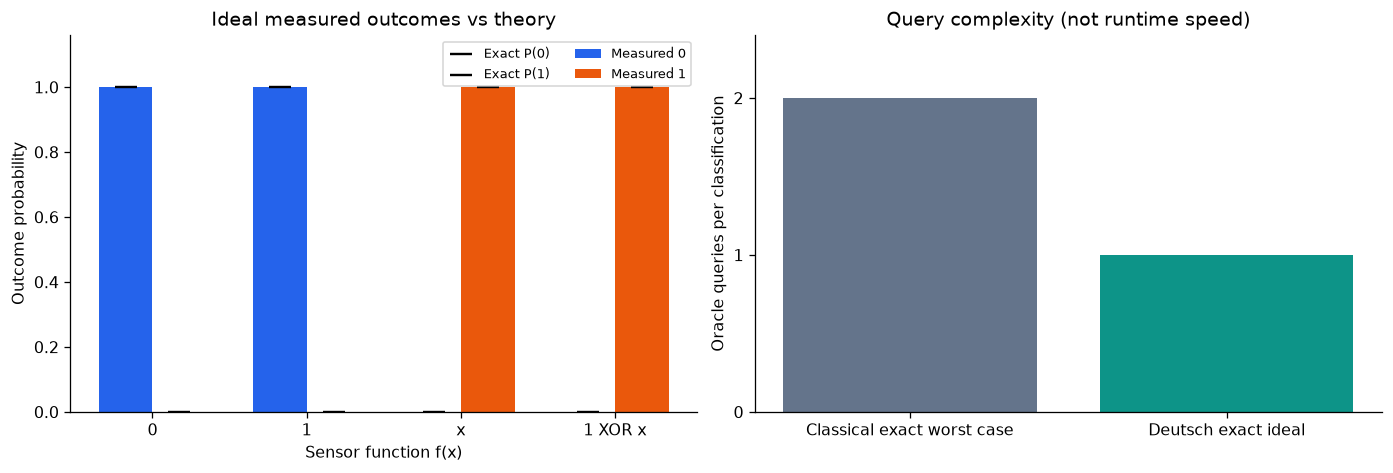

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
x = np.arange(len(keys)); width = .35
for bit, color in [(0, '#2563eb'), (1, '#ea580c')]:
    measured = [ideal_counts[k].get(str(bit), 0)/SHOTS for k in keys]
    axes[0].bar(x + (bit-.5)*width, measured, width, label=f'Measured {bit}', color=color)
    exact = results[f'P({bit}) exact'].to_numpy()
    axes[0].scatter(x + (bit-.5)*width, exact, marker='_', s=180, color='black',
                    label=f'Exact P({bit})')
axes[0].set(xticks=x, xticklabels=['0', '1', 'x', '1 XOR x'], ylim=(0, 1.16),
            xlabel='Sensor function f(x)', ylabel='Outcome probability', title='Ideal measured outcomes vs theory')
axes[0].legend(fontsize=8, ncol=2)
axes[1].bar(['Classical exact worst case', 'Deutsch exact ideal'], [2, 1], color=['#64748b','#0d9488'])
axes[1].set(ylabel='Oracle queries per classification', title='Query complexity (not runtime speed)', yticks=[0, 1, 2], ylim=(0, 2.4))
plt.show()

## 7. Inspect interference through Bloch vectors
A reduced input-qubit state can be described by $(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$. Before the oracle, it is $|+\rangle$ with vector $(1,0,0)$. A constant rule leaves that vector unchanged; a balanced rule produces $|-\rangle$ with vector $(-1,0,0)$. The final Hadamard maps these to north/south poles, $|0\rangle$/$|1\rangle$.

The plot below is a component trace rather than a 3D Bloch sphere, so the phase-to-measurement change is easy to compare across all four functions.

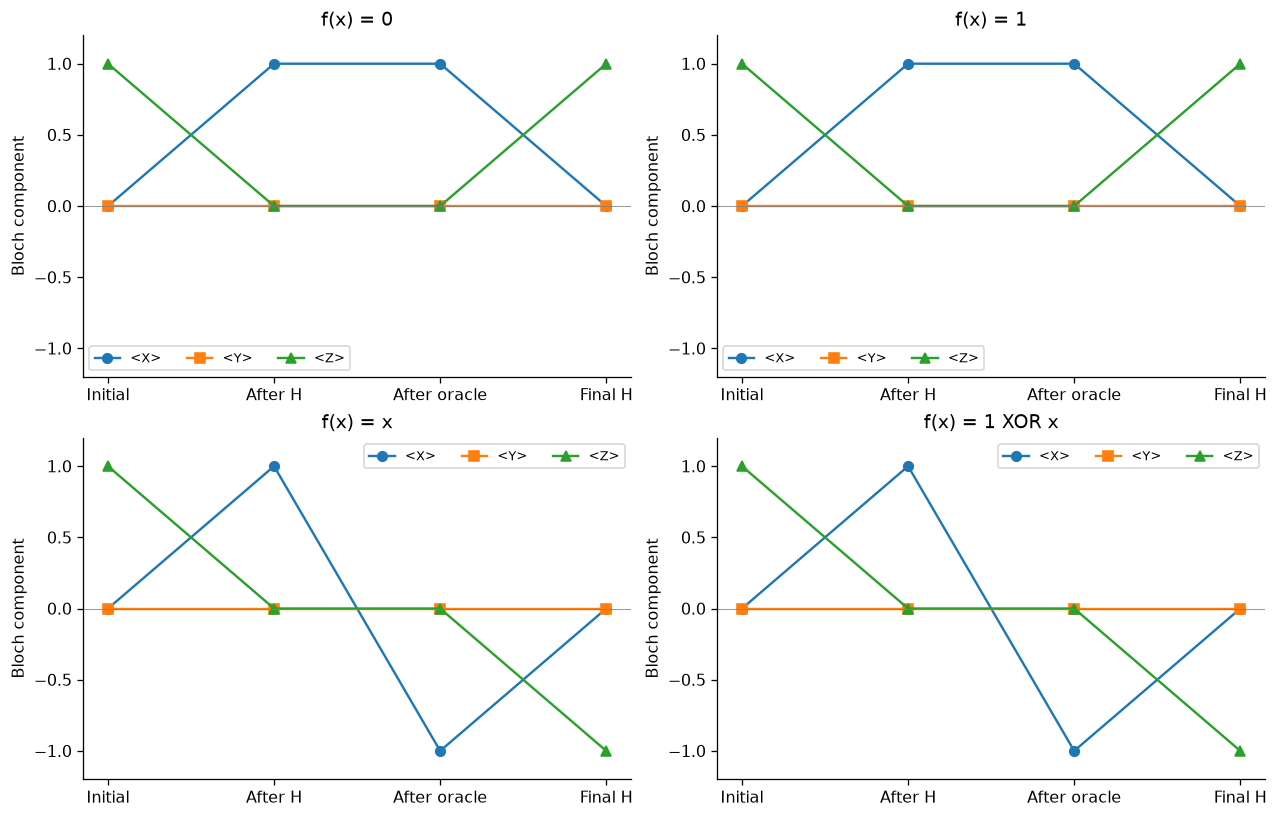

PASS: within-class final states are equivalent up to global phase.


In [8]:
def stage_vectors(key):
    qc = QuantumCircuit(2)
    vectors = []
    def record():
        rho_input = partial_trace(Statevector.from_instruction(qc), [1])
        vectors.append([float(np.real(rho_input.expectation_value(Pauli(p)))) for p in 'XYZ'])
    record()
    qc.x(1); qc.h(0); qc.h(1); record()
    qc.append(build_oracle(key).to_gate(), [0, 1]); record()
    qc.h(0); record()
    return np.array(vectors)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, key in zip(axes.flat, keys):
    vectors = stage_vectors(key)
    for j, component in enumerate('XYZ'):
        ax.plot(range(4), vectors[:, j], marker=['o','s','^'][j], label=f'<{component}>')
    ax.set(title=SENSORS[key]['label'], xticks=range(4),
           xticklabels=['Initial', 'After H', 'After oracle', 'Final H'], ylim=(-1.2,1.2), ylabel='Bloch component')
    ax.axhline(0, color='gray', lw=.5); ax.legend(ncol=3, fontsize=8)
plt.show()
# Opposite functions within the same class differ only by global phase.
for a, b in [('constant_0','constant_1'), ('balanced_x','balanced_not_x')]:
    assert Statevector.from_instruction(deutsch_circuit(a,False)).equiv(
        Statevector.from_instruction(deutsch_circuit(b,False)))
print('PASS: within-class final states are equivalent up to global phase.')

## 8. Extension: synthetic measurement errors
This optional experiment adds a symmetric readout error to the measured input bit: it flips with probability $p$. Gates and state preparation remain ideal. This is **not** a calibrated hardware model or a test of gate noise.

For this model, each one-query execution is correct with probability $1-p$. Repetition can improve a majority-vote decision for $p<0.5$, but costs more queries and loses the exact one-query guarantee. The plot reports **per-shot** accuracy, not majority-vote accuracy. Error bars are 95% Wilson binomial intervals (including boundary cases), and are conditional on this artificial independent-error model.

,Oracle,Readout flip p,Correct,Shots,Accuracy,Low,High
0,constant_0,0.00,2048,2048,1.0000,0.9981,1.0000
1,constant_1,0.00,2048,2048,1.0000,0.9981,1.0000
2,balanced_x,0.00,2048,2048,1.0000,0.9981,1.0000
3,balanced_not_x,0.00,2048,2048,1.0000,0.9981,1.0000
4,constant_0,0.02,2012,2048,0.9824,0.9758,0.9873
5,constant_1,0.02,2005,2048,0.9790,0.9718,0.9844
6,balanced_x,0.02,2011,2048,0.9819,0.9752,0.9869
7,balanced_not_x,0.02,2001,2048,0.9771,0.9696,0.9827
8,constant_0,0.05,1937,2048,0.9458,0.9351,0.9548
9,constant_1,0.05,1957,2048,0.9556,0.9458,0.9637


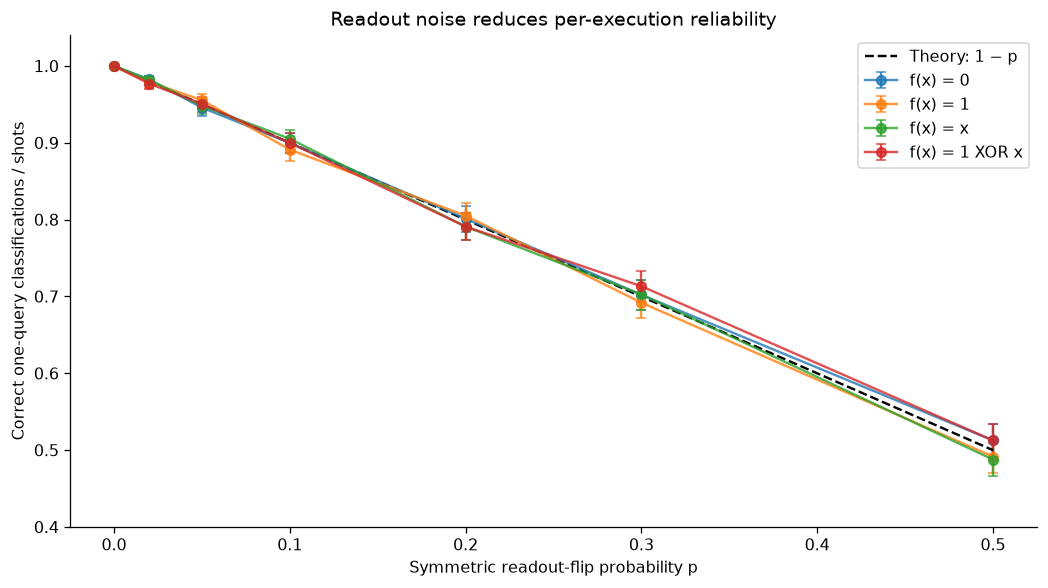

PASS: zero-noise baseline is exact. Nonzero-noise values are sampled estimates.


In [9]:
NOISE_SHOTS = 2048
ERROR_RATES = np.array([0, .02, .05, .10, .20, .30, .50])

def wilson_interval(successes, total, z=1.96):
    phat = successes / total
    denom = 1 + z*z/total
    center = (phat + z*z/(2*total))/denom
    radius = z*np.sqrt(phat*(1-phat)/total + z*z/(4*total*total))/denom
    return max(0.0, center-radius), min(1.0, center+radius)

noise_rows = []
for j, p in enumerate(ERROR_RATES):
    noise = NoiseModel()
    if p > 0:
        noise.add_readout_error(ReadoutError([[1-p,p],[p,1-p]]), [0])
    backend = AerSimulator(noise_model=noise)
    circuits = transpile([deutsch_circuit(k) for k in keys], backend,
                         optimization_level=0, seed_transpiler=SEED)
    batch = backend.run(circuits, shots=NOISE_SHOTS, seed_simulator=SEED+j).result()
    for i, key in enumerate(keys):
        expected = SENSORS[key]['truth'][0] ^ SENSORS[key]['truth'][1]
        counts = batch.get_counts(i)
        successes = counts.get(str(expected), 0)
        low, high = wilson_interval(successes, NOISE_SHOTS)
        noise_rows.append({'Oracle': key, 'Readout flip p': float(p),
                           'Correct': successes, 'Shots': NOISE_SHOTS,
                           'Accuracy': successes/NOISE_SHOTS, 'Low': low, 'High': high})
noise_results = pd.DataFrame(noise_rows)
display(noise_results.round(4))
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for key in keys:
    frame = noise_results[noise_results['Oracle'] == key]
    acc = frame['Accuracy'].to_numpy()
    ax.errorbar(frame['Readout flip p'], acc,
                yerr=np.maximum(0, np.vstack([acc-frame['Low'], frame['High']-acc])),
                marker='o', capsize=3, label=SENSORS[key]['label'], alpha=.8)
ax.plot(ERROR_RATES, 1-ERROR_RATES, 'k--', label='Theory: 1 − p')
ax.set(xlabel='Symmetric readout-flip probability p', ylabel='Correct one-query classifications / shots',
       title='Readout noise reduces per-execution reliability', ylim=(.4,1.04))
ax.legend(); plt.show()
assert (noise_results.query('`Readout flip p` == 0')['Accuracy'] == 1).all()
print('PASS: zero-noise baseline is exact. Nonzero-noise values are sampled estimates.')

## 9. Optional interactive sensor explorer
This control reruns a selected one-query circuit with a chosen shot count and readout-error probability. The static results above remain sufficient for the report. In Colab, widget support is enabled when available; in a viewer without widgets, call `explore_sensor(...)` directly. Changing shots changes the number of repeated executions, not the oracle calls inside a circuit.

In [10]:
def explore_sensor(sensor='balanced_x', shots=1024, readout_error=0.0):
    if sensor not in SENSORS or not isinstance(shots, (int, np.integer)) or shots < 1:
        raise ValueError('Choose a listed sensor and a positive integer shot count.')
    if not 0 <= readout_error <= .5:
        raise ValueError('Readout error must be between 0 and 0.5.')
    model = NoiseModel()
    if readout_error:
        p = float(readout_error)
        model.add_readout_error(ReadoutError([[1-p,p],[p,1-p]]), [0])
    backend = AerSimulator(noise_model=model)
    circuit = deutsch_circuit(sensor)
    compiled = transpile(circuit, backend, optimization_level=0, seed_transpiler=SEED)
    counts = backend.run(compiled, shots=int(shots), seed_simulator=SEED).result().get_counts()
    display(circuit.draw('mpl')); plt.close('all')
    fig, ax = plt.subplots(figsize=(5,3))
    ax.bar(['0: faulty', '1: working'], [counts.get('0',0), counts.get('1',0)],
           color=['#2563eb','#ea580c'])
    ax.set(title=SENSORS[sensor]['label'], ylabel='Counts', ylim=(0,shots*1.1))
    plt.show()
    print('Counts:', counts, '| Oracle calls per execution: 1 | Executions:', shots)

try:
    import ipywidgets as widgets
    try:
        from google.colab import output
        output.enable_custom_widget_manager()
    except ImportError:
        pass
    controls = widgets.interactive(
        explore_sensor,
        sensor=widgets.Dropdown(options=[(v['label'],k) for k,v in SENSORS.items()], value='balanced_x'),
        shots=widgets.SelectionSlider(options=[1,128,512,1024,4096], value=1024, continuous_update=False),
        readout_error=widgets.FloatSlider(min=0,max=.5,step=.05,value=0,continuous_update=False))
    display(controls)
except ImportError:
    print('Widgets unavailable; call explore_sensor directly.')

interactive(children=(Dropdown(description='sensor', index=2, options=(('f(x) = 0', 'constant_0'), ('f(x) = 1'…

## 10. Analysis and interpretation
- **Constant zero and constant one:** both produce input measurement `0`, so the sensor is faulty. The functions differ, but the promised classification is identical.
- **Identity and inverted identity:** both produce `1`, so the sensor is working. Their final states differ only by global phase.
- **Why classical exact classification needs two queries:** after one evaluation, either observed bit is compatible with a constant function and a balanced function. Evaluating both inputs resolves the ambiguity. A randomized one-query classifier can guess, but cannot guarantee correctness on every function (under a uniform prior, the best average success is 1/2).
- **What the quantum advantage means:** one coherent query instead of two for exact ideal classification. Gate construction, compilation, state preparation, and sampling also have costs. A classical computer simulates this two-qubit circuit easily; this project makes no wall-clock speedup claim.
- **Noise findings:** ideal classification is deterministic. Under the readout-only model, expected accuracy is $1-p$ for every oracle. Finite-shot estimates fluctuate around that line; at $p=0.5$ the readout carries no class information.
- **Application limitation:** a constant physical sensor could be legitimate for some physical processes. Calling it faulty is the assignment’s rule, not a universal engineering diagnosis. Extending this to real sensors needs a physical specification and a realizable coherent interface.

### Query versus circuit resources
The algorithm uses two qubits and one measured classical bit. Outside the oracle, it uses one X and three H gates. Oracle decompositions use I, X, CX, or CX+X, respectively. An oracle query is counted as one invocation regardless of this internal gate count. The all-functions ideal experiment uses $4\times\texttt{SHOTS}$ queries; the noise sweep uses $4\times7\times\texttt{NOISE\_SHOTS}$ additional queries. Oracle-validation tests and the interactive explorer are separate experiments.

## 11. Conclusion, limitations, and presentation checklist
**Conclusion:** Deutsch’s algorithm determines whether each simulated one-bit sensor is faulty or working using exactly one logical oracle query per ideal execution. All four oracle truth tables are checked independently, and sampled ideal results are checked against exact probabilities. Noise demonstrates the difference between ideal certainty and experimental reliability.

**Limitations:** simulator execution, no hardware calibration, no gate/decoherence errors, no real sensor integration, no error-correcting code, and no benchmark establishing practical acceleration. Colab execution is supported by the setup cell, but validation recorded here was performed in a local Python environment rather than the Google Colab service.

**Before your individual presentation:**
1. Add your name and register number; follow your course’s assistance-disclosure policy.
2. Run all cells in Colab; verify the printed package versions and all PASS messages.
3. Explain why the auxiliary starts in |1⟩ and becomes |−⟩.
4. Explain the distinction between one query per execution and 1024 repeated executions.
5. Change `SHOTS` or a noise rate and write your own observation about the resulting graph.

### Viva / self-check
- What fails if the auxiliary starts in |+⟩? *(X|+⟩ = |+⟩, so no useful phase kickback.)*
- Can the result identify which constant function was used? *(No; global phase does not distinguish them.)*
- Why does a CX not imply the two qubits are entangled here? *(The target is an X eigenstate, so the output factors.)*
- Why do we measure only the input qubit? *(It stores the class bit; the auxiliary remains |−⟩.)*
- Does a noisy majority vote still use a single total query? *(No; each repetition is another query.)*

### References
1. Deutsch, D. (1985), “Quantum theory, the Church–Turing principle and the universal quantum computer,” *Proceedings of the Royal Society A*, 400, 97–117. https://doi.org/10.1098/rspa.1985.0070
2. IBM Quantum, Deutsch–Jozsa algorithm (Deutsch’s problem is the one-input-bit case): https://quantum.cloud.ibm.com/learning/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm
3. Qiskit circuit API: https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit
4. Qiskit Aer noise documentation: https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.ReadoutError.html
5. Google Colab notebook guide: https://colab.research.google.com/notebooks/intro.ipynb